# Redundancy (rank correlation) and in-sample IC

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

chars = [c for c in char_names()]
df = rank_normalise(is_universe(), chars + ["ret"])

## Average monthly Spearman correlation (pairwise-complete)

In [3]:
P = len(chars); C_sum = np.zeros((P, P)); C_cnt = np.zeros((P, P)); ics = []
for _, g in df.group_by("DATE", maintain_order=True):
    X = g.select(chars).to_numpy(); r = g["ret"].to_numpy()
    M = ~np.isnan(X); Z = np.where(M, X, 0.0); Mf = M.astype(float)
    n = Mf.T @ Mf; sx = Z.T @ Mf; sxx = (Z ** 2).T @ Mf; sxy = Z.T @ Z
    with np.errstate(invalid="ignore", divide="ignore"):
        cov = sxy / n - (sx / n) * (sx.T / n)
        var = sxx / n - (sx / n) ** 2
        C = cov / np.sqrt(var * var.T)
    ok = (n > 100) & np.isfinite(C)
    C_sum += np.where(ok, C, 0); C_cnt += ok
    ics.append([np.corrcoef(X[M[:, k], k], r[M[:, k]])[0, 1] if M[:, k].sum() > 100 else np.nan for k in range(P)])
corr = C_sum / C_cnt
np.fill_diagonal(corr, 1.0)
ics = np.array(ics)

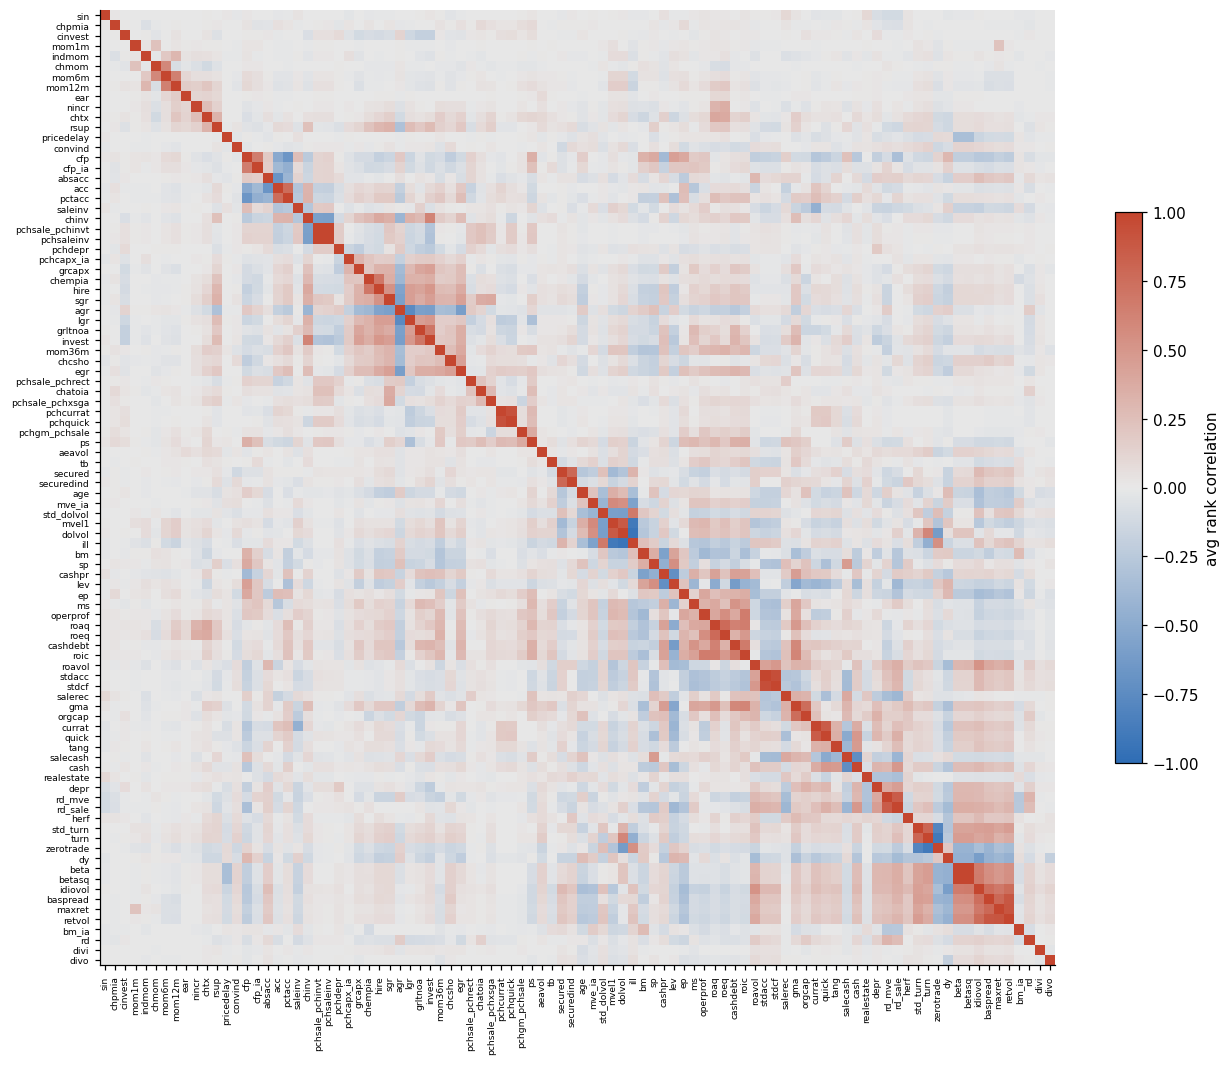

In [4]:
dist = squareform(1 - np.abs(corr), checks=False)
order = leaves_list(linkage(dist, "average"))
fig, ax = plt.subplots(figsize=(14, 13))
im = ax.imshow(corr[np.ix_(order, order)], cmap=DIVERGING, vmin=-1, vmax=1)
names = [chars[i] for i in order]
ax.set_xticks(range(P), names, rotation=90, fontsize=6); ax.set_yticks(range(P), names, fontsize=6)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.5, label="avg rank correlation"); plt.show()

## Number of pairs above each |correlation| threshold

In [5]:
iu = np.triu_indices(P, 1)
pl.DataFrame({"threshold": [0.95, 0.9, 0.85, 0.8, 0.75, 0.7],
              "pairs": [int((np.abs(corr[iu]) > t).sum()) for t in [0.95, 0.9, 0.85, 0.8, 0.75, 0.7]]})

threshold,pairs
f64,i64
0.9500,2
0.9000,6
0.8500,12
0.8000,14
0.7500,21
0.7000,25


## In-sample IC: monthly rank correlation with the same-month return

In [6]:
ic_mean = np.nanmean(ics, 0)
ic_t = ic_mean / (np.nanstd(ics, 0, ddof=1) / np.sqrt((~np.isnan(ics)).sum(0)))
missing = [df[c].null_count() / df.height for c in chars]
ic = pl.DataFrame({"char": chars, "missing": missing, "ic_mean": ic_mean, "ic_t": ic_t})
ic.sort(pl.col("ic_t").abs(), descending=True)

char,missing,ic_mean,ic_t
str,f64,f64,f64
"""cfp_ia""",0.2522,0.0249,7.6247
"""ear""",0.2396,0.0143,6.3565
"""ep""",0.1907,0.0390,6.1954
"""operprof""",0.2590,0.0306,6.1335
"""roic""",0.2150,0.0294,6.1334
"""cfp""",0.2522,0.0372,6.0245
"""tb""",0.2817,0.0186,5.9947
"""nincr""",0.2393,0.0180,5.9376
"""roeq""",0.2448,0.0304,5.9001


## Pairs with |correlation| > 0.7

In [7]:
info = {r["char"]: r for r in ic.iter_rows(named=True)}
pairs = [{"a": chars[i], "b": chars[j], "rho": corr[i, j],
          "missing_a": info[chars[i]]["missing"], "missing_b": info[chars[j]]["missing"],
          "ic_t_a": info[chars[i]]["ic_t"], "ic_t_b": info[chars[j]]["ic_t"]}
         for i, j in zip(*iu) if abs(corr[i, j]) > 0.7]
pl.DataFrame(pairs).sort(pl.col("rho").abs(), descending=True)

a,b,rho,missing_a,missing_b,ic_t_a,ic_t_b
str,str,f64,f64,f64,f64,f64
"""beta""","""betasq""",0.9972,0.0698,0.0698,-0.9497,-0.9639
"""pchsale_pchinvt""","""pchsaleinv""",0.9956,0.4053,0.4105,3.3504,3.7972
"""stdacc""","""stdcf""",0.9452,0.4832,0.4832,-4.1062,-4.0260
"""dolvol""","""ill""",-0.9324,0.0092,0.0003,2.4374,-3.9516
"""pchcurrat""","""pchquick""",0.9283,0.2742,0.2791,-1.4853,-0.9075
"""maxret""","""retvol""",0.9015,0.0000,0.0006,-2.8937,-2.2563
"""turn""","""zerotrade""",-0.8941,0.0109,0.0000,0.3571,-1.7241
"""mvel1""","""ill""",-0.8926,0.0000,0.0003,3.4149,-3.9516
"""baspread""","""retvol""",0.8894,0.0000,0.0006,-1.6758,-2.2563


## Selected pairs

In [8]:
ix = {c: i for i, c in enumerate(chars)}
sel = [("acc", "absacc"), ("acc", "pctacc"), ("ps", "ms"), ("ps", "nincr"), ("ms", "nincr"), ("ps", "roaq"),
       ("rd", "rd_mve"), ("rd_mve", "rd_sale"), ("secured", "securedind"), ("herf", "indmom"), ("mvel1", "mve_ia"),
       ("bm", "bm_ia"), ("cfp", "cfp_ia"), ("pchsaleinv", "saleinv"), ("pchsaleinv", "pchsale_pchinvt"), ("divi", "divo")]
pl.DataFrame([{"a": a, "b": b, "rho": corr[ix[a], ix[b]]} for a, b in sel])

a,b,rho
str,str,f64
"""acc""","""absacc""",-0.6735
"""acc""","""pctacc""",0.7575
"""ps""","""ms""",0.2912
"""ps""","""nincr""",-0.0062
"""ms""","""nincr""",0.0114
"""ps""","""roaq""",0.2967
"""rd""","""rd_mve""",0.3138
"""rd_mve""","""rd_sale""",0.8516
"""secured""","""securedind""",0.7863
